# **BLOCO 1**

**Instalação do DuckDB**

In [132]:
!pip install duckdb -q

**Conexão ao Drive**

In [133]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Conferência dos arquivos**

In [134]:
import os
caminho = '/content/drive/MyDrive/Olist'
os.listdir(caminho)

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

**Criação das tabelas no DuckDB**

In [135]:
import duckdb

con = duckdb.connect()  # banco em memória

arquivos = {
    'customers': 'olist_customers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'order_payments': 'olist_order_payments_dataset.csv',
    'order_reviews': 'olist_order_reviews_dataset.csv',
    'orders': 'olist_orders_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'category_translation': 'product_category_name_translation.csv',
}

for tabela, arq in arquivos.items():
    con.execute(
        f"CREATE OR REPLACE TABLE {tabela} AS "
        f"SELECT * FROM read_csv_auto('{caminho}/{arq}')"
    )

**Contagem das linhas em cada tabela**

In [136]:
for t in arquivos:
    n = con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    print(t, n)

customers 99441
geolocation 1000163
order_items 112650
order_payments 103886
order_reviews 100000
orders 99441
products 32951
sellers 3095
category_translation 71


O campo **order_reviews** está com exatamente 100000 linhas, um número bem redondo. Vamos verificar antes de analisar.

**Tipos das colunas**

In [137]:
con.execute("DESCRIBE orders").df()

,column_name,column_type,null,key,default,extra
0,order_id,VARCHAR,YES,None,None,None
1,customer_id,VARCHAR,YES,None,None,None
2,order_status,VARCHAR,YES,None,None,None
3,order_purchase_timestamp,TIMESTAMP,YES,None,None,None
4,order_approved_at,TIMESTAMP,YES,None,None,None
5,order_delivered_carrier_date,TIMESTAMP,YES,None,None,None
6,order_delivered_customer_date,TIMESTAMP,YES,None,None,None
7,order_estimated_delivery_date,TIMESTAMP,YES,None,None,None


**Reviews**

In [138]:
con.execute("""
    SELECT COUNT(*) AS linhas,
           COUNT(DISTINCT review_id) AS reviews_unicos,
           COUNT(*) FILTER (WHERE review_id IS NULL) AS review_id_nulo,
           COUNT(*) FILTER (WHERE review_score IS NULL) AS nota_nula
    FROM order_reviews
""").df()

,linhas,reviews_unicos,review_id_nulo,nota_nula
0,100000,99173,0,0


**Status dos pedidos**

In [139]:
con.execute("""
    SELECT order_status, COUNT(*) AS pedidos
    FROM orders
    GROUP BY 1
    ORDER BY 2 DESC
""").df()

,order_status,pedidos
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


**Período coberto**

In [140]:
con.execute("""
    SELECT MIN(order_purchase_timestamp) AS primeiro_pedido,
           MAX(order_purchase_timestamp) AS ultimo_pedido
    FROM orders
""").df()

,primeiro_pedido,ultimo_pedido
0,2016-09-04 21:15:19,2018-10-17 17:30:18


# **BLOCO 2**

**Pergunta 1: como evoluiu a receita mês a mês?**

Defini receita como a soma de price em order_items, sem o frete, e desconsiderei pedidos cancelados e indisponíveis.

Os meses das "pontas" continham um número de pedidos muito fora do esperado, por isso foram retirados da análise.

In [141]:
query_receita = """
    WITH receita_mensal AS (
        SELECT date_trunc('month', o.order_purchase_timestamp) AS mes,
               COUNT(DISTINCT o.order_id) AS pedidos,
               SUM(oi.price) AS receita
        FROM orders o
        JOIN order_items oi ON oi.order_id = o.order_id
        WHERE o.order_status NOT IN ('canceled', 'unavailable')
          AND o.order_purchase_timestamp >= '2017-01-01'
          AND o.order_purchase_timestamp <  '2018-09-01'
        GROUP BY 1
    ),
    com_variacoes AS (
        SELECT mes, pedidos, receita,
               receita / pedidos AS ticket_medio,
               100.0 * (receita / LAG(receita, 1)  OVER (ORDER BY mes) - 1) AS var_mensal_pct,
               100.0 * (receita / LAG(receita, 12) OVER (ORDER BY mes) - 1) AS var_anual_pct
        FROM receita_mensal
    )
    SELECT mes, pedidos,
           ROUND(receita, 2)        AS receita,
           ROUND(ticket_medio, 2)   AS ticket_medio,
           ROUND(var_mensal_pct, 1) AS var_mensal_pct,
           ROUND(var_anual_pct, 1)  AS var_anual_pct
    FROM com_variacoes
    ORDER BY mes
"""
df_receita = con.execute(query_receita).df()
df_receita

,mes,pedidos,receita,ticket_medio,var_mensal_pct,var_anual_pct
0,2017-01-01,787,120098.27,152.60,NaN,NaN
1,2017-02-01,1718,244959.35,142.58,104.0,NaN
2,2017-03-01,2617,368341.32,140.75,50.4,NaN
3,2017-04-01,2377,353842.98,148.86,-3.9,NaN
4,2017-05-01,3640,503159.19,138.23,42.2,NaN
5,2017-06-01,3205,429916.61,134.14,-14.6,NaN
6,2017-07-01,3946,492287.30,124.76,14.5,NaN
7,2017-08-01,4272,568245.79,133.02,15.4,NaN
8,2017-09-01,4227,621415.91,147.01,9.4,NaN
9,2017-10-01,4547,660179.62,145.19,6.2,NaN


**O que os dados nos mostram:**

**Validação**

Tipos: as colunas de data vieram como TIMESTAMP, então não precisa de conversão

Status: os pedidos somam 99.441, igual à tabela orders. 97% foram entregues (96.478). Os 1.234 pedidos canceled e unavailable (1,2%) ficam fora da receita.

Período: de 04/09/2016 a 17/10/2018.

Reviews: são 100.000 linhas, mas só 99.173 review_id distintos, ou seja, 827 repetidos. Vamos investigar se há linhas duplicadas.

**Receita mensal**

Os extremos distorciam a análise. Set/2016 tem 2 pedidos, out/2016 tem 290, dez/2016 tem 1, e set/2018 tem 1 pedido de 145 reais.

Isso é início e fim de coleta, não desempenho.

Havia um buraco em nov/2016 (nenhum pedido).

Janela confiável: jan/2017 a ago/2018 (20 meses completos).

Pico em nov/2017: 1 milhão de reais (+52,1%). Será averiguado se é período de  "Black Friday" (24/11/2017).

Estagnação em 2018: de mar a ago/2018 a receita ficou entre 850 mil reais e 990 mil reais, sem tendência de alta.

Comparando com o mesmo mês do ano anterior: mar/2018 +166%, mai/2018 +97%, ago/2018 +49%.

O crescimento anual desacelera forte.

O ticket médio é estável: receita ÷ pedidos fica entre ~125 reais e ~150 reais na maior parte dos meses.

Logo, o crescimento veio de volume de pedidos, não de preço.

**Gráfico**

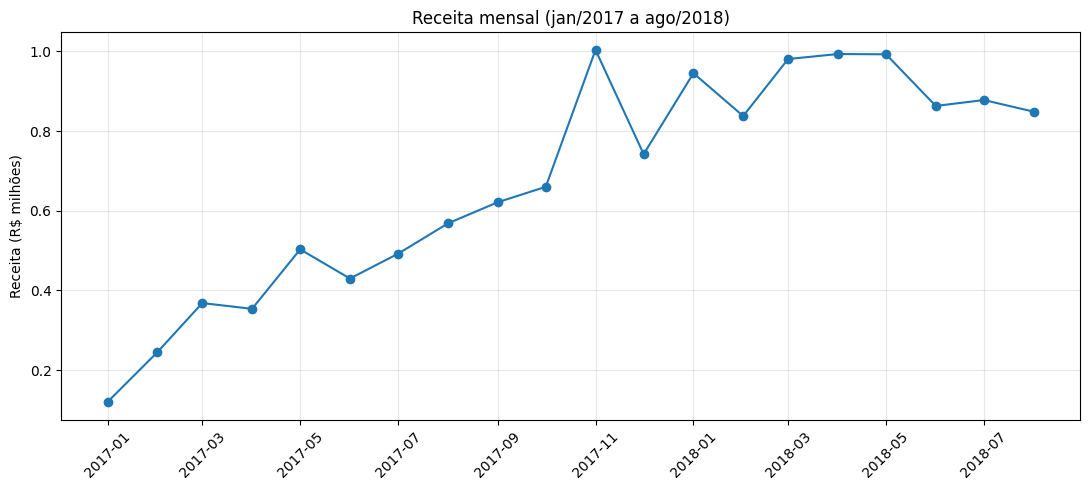

In [142]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df_receita['mes'], df_receita['receita'] / 1e6, marker='o')
ax.set_title('Receita mensal (jan/2017 a ago/2018)')
ax.set_ylabel('Receita (R$ milhões)')
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('receita_mensal.png', dpi=150, bbox_inches='tight')
plt.show()

**Duas verificações**

A. Black Friday: os dias de maior receita em novembro/2017

In [143]:
con.execute("""
    SELECT CAST(o.order_purchase_timestamp AS DATE) AS dia,
           COUNT(DISTINCT o.order_id) AS pedidos,
           ROUND(SUM(oi.price), 2) AS receita
    FROM orders o
    JOIN order_items oi ON oi.order_id = o.order_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
      AND o.order_purchase_timestamp >= '2017-11-01'
      AND o.order_purchase_timestamp <  '2017-12-01'
    GROUP BY 1
    ORDER BY receita DESC
    LIMIT 5
""").df()

,dia,pedidos,receita
0,2017-11-24,1166,152653.74
1,2017-11-25,498,60923.48
2,2017-11-27,400,47923.66
3,2017-11-28,376,47886.55
4,2017-11-26,387,44976.28


B. Reviews repetidos

In [144]:
con.execute("""
    SELECT review_id,
           COUNT(*) AS linhas,
           COUNT(DISTINCT order_id) AS pedidos_distintos
    FROM order_reviews
    GROUP BY 1
    HAVING COUNT(*) > 1
    ORDER BY linhas DESC
    LIMIT 10
""").df()

,review_id,linhas,pedidos_distintos
0,2d6ac45f859465b5c185274a1c929637,3,3
1,44e9f871226d8a130de3fc39dfbdf0c5,3,3
2,f4bb9d6dd4fb6dcc2298f0e7b17b8e1e,3,3
3,dbdf1ea31790c8ecfcc6750525661a9b,3,3
4,69a1068c3128a14994e3e422e4539e04,3,3
5,7b606b0d57b078384f0b58eac1d41d78,3,3
6,32415bbf6e341d5d517080a796f79b5c,3,3
7,39b4603793c1c7f5f36d809b4a218664,3,3
8,832acec9bbf4efe65c3fb6423d8b4ed7,3,3
9,70509c441d994fa03d6c1457930c9024,3,3


In [145]:
con.execute("""
    SELECT COUNT(*) AS pedidos_com_mais_de_uma_avaliacao
    FROM (
        SELECT order_id
        FROM order_reviews
        GROUP BY 1
        HAVING COUNT(*) > 1
    )
""").df()

,pedidos_com_mais_de_uma_avaliacao
0,555


**Interpretação**

**Receita mensal (query revisada)**

var_anual_pct só aparece a partir de jan/2018, como esperado.

A variação anual cai de +687% em jan/2018 para +49% em ago/2018. Parte disso é efeito de base: 2017 foi a fase de largada da operação, então qualquer comparação contra ela parece enorme. O dado relevante é a tendência de desaceleração.

O ticket médio fica entre 125 reais e 153 reais nos 20 meses, sem tendência clara. O crescimento veio de volume de pedidos, não de aumento de preço.

**Black Friday (verificação A): confirmada**

24/11/2017 teve 1.166 pedidos e 152,7 mil reais, mais que o dobro do segundo maior dia (498 pedidos, em 25/11).

Novembro teve 7.421 pedidos em 30 dias, média de ~247 por dia. Ou seja, o pico foi mais de 4 vezes a média diária.

Os quatro dias seguintes também ficaram entre os cinco maiores do mês, todos acima de 370 pedidos.

A queda de 26,1% em dezembro pode ser antecipação de compras para a Black Friday. Isso é hipótese: os dados mostram a queda, mas não a causa.

**Reviews (verificação B):**

Os review_id repetidos aparecem em pedidos diferentes (3 linhas = 3 pedidos distintos). Não são linhas duplicadas, é o mesmo identificador reaproveitado.

555 pedidos têm mais de uma avaliação.

Rewduzido a uma avaliação por pedido (a mais recente).

**Visão corrigida**

In [146]:
con.execute("""
    CREATE OR REPLACE VIEW reviews_por_pedido AS
    SELECT * EXCLUDE (rn)
    FROM (
        SELECT *,
               ROW_NUMBER() OVER (
                   PARTITION BY order_id
                   ORDER BY review_answer_timestamp DESC
               ) AS rn
        FROM order_reviews
    )
    WHERE rn = 1
""")

con.execute("""
    SELECT COUNT(*) AS linhas, COUNT(DISTINCT order_id) AS pedidos_distintos
    FROM reviews_por_pedido
""").df()

,linhas,pedidos_distintos
0,99441,99441


**Pergunta 2: quais categorias concentram a receita?**

Os nomes das categorias estão em português e alguns produtos não têm categoria ou não constam na tradução. Por isso foi usado o LEFT JOIN com COALESCE.

In [147]:
query_categorias = """
    WITH receita_categoria AS (
        SELECT COALESCE(t.product_category_name_english,
                        p.product_category_name,
                        'sem_categoria') AS categoria,
               COUNT(DISTINCT o.order_id) AS pedidos,
               SUM(oi.price) AS receita
        FROM orders o
        JOIN order_items oi ON oi.order_id = o.order_id
        JOIN products p ON p.product_id = oi.product_id
        LEFT JOIN category_translation t
               ON t.product_category_name = p.product_category_name
        WHERE o.order_status NOT IN ('canceled', 'unavailable')
          AND o.order_purchase_timestamp >= '2017-01-01'
          AND o.order_purchase_timestamp <  '2018-09-01'
        GROUP BY 1
    )
    SELECT categoria,
           pedidos,
           ROUND(receita, 2) AS receita,
           ROUND(100.0 * receita / SUM(receita) OVER (), 1) AS pct_receita,
           ROUND(100.0 * SUM(receita) OVER (
                    ORDER BY receita DESC
                    ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
                 / SUM(receita) OVER (), 1) AS pct_acumulado
    FROM receita_categoria
    ORDER BY receita DESC
    LIMIT 15
"""
df_categorias = con.execute(query_categorias).df()
df_categorias

,categoria,pedidos,receita,pct_receita,pct_acumulado
0,health_beauty,8757,1251145.54,9.3,9.3
1,watches_gifts,5599,1194824.97,8.9,18.2
2,bed_bath_table,9394,1035485.07,7.7,25.9
3,sports_leisure,7656,977728.77,7.3,33.2
4,computers_accessories,6636,902922.70,6.7,39.9
5,furniture_decor,6373,721584.27,5.4,45.2
6,housewares,5838,625538.73,4.7,49.9
7,cool_stuff,3609,619724.39,4.6,54.5
8,auto,3863,585177.48,4.4,58.8
9,garden_tools,3500,479650.06,3.6,62.4


**Concentração**

Nenhuma categoria passa de 10% da receita. A maior, health_beauty, tem 9,3%.

As 7 primeiras categorias somam 49,9% da receita. As 15 primeiras somam 76,3%.

A tabela de tradução tem 71 categorias, então cerca de 21% delas geram mais de três quartos da receita, perto do clássico 80/20.

Dividindo a receita pelos pedidos de cada categoria, temos:

Categoria	Pedidos	Receita por pedido
office_furniture	1.266	~215 reais
watches_gifts	5.599	~213 reais
health_beauty	8.757	~143 reais
bed_bath_table	9.394	~110 reais
telephony	4.175	~77 reais

bed_bath_table tem mais pedidos, mas fica em 3º lugar em receita.

watches_gifts tem 40% menos pedidos que health_beauty e quase a mesma receita, porque o valor por pedido é bem maior.

Não somei os pedidos para se ter o total de pedidos, pois no mesmo pedido, podemos ter a compra de itens de categorias diferentes, o que garia com que o número de pedidos "inflasse".

**Pergunta 3: desempenho por estado e prazo de entrega**

Duas premissas novas: o estado é o do comprador (customer_state) e a análise de prazo usa só pedidos entregues. Em customers, o customer_id muda a cada pedido; quem identifica a pessoa é o customer_unique_id.

**3a. Receita por estado**

In [148]:
con.execute("""
    SELECT c.customer_state AS estado,
           COUNT(DISTINCT o.order_id) AS pedidos,
           ROUND(SUM(oi.price), 2) AS receita,
           ROUND(100.0 * SUM(oi.price) / SUM(SUM(oi.price)) OVER (), 1) AS pct_receita,
           ROUND(SUM(oi.price) / COUNT(DISTINCT o.order_id), 2) AS receita_por_pedido
    FROM orders o
    JOIN order_items oi ON oi.order_id = o.order_id
    JOIN customers c    ON c.customer_id = o.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY 1
    ORDER BY receita DESC
    LIMIT 10
""").df()

,estado,pedidos,receita,pct_receita,receita_por_pedido
0,SP,41021,5150778.70,38.3,125.56
1,RJ,12654,1802436.24,13.4,142.44
2,MG,11457,1568855.98,11.7,136.93
3,RS,5395,739357.46,5.5,137.04
4,PR,4962,674867.55,5.0,136.01
5,SC,3590,516340.22,3.8,143.83
6,BA,3340,506214.78,3.8,151.56
7,DF,2114,299842.68,2.2,141.84
8,GO,1990,286886.07,2.1,144.16
9,ES,2014,272614.34,2.0,135.36


SP concentra 38,3% da receita, e SP, RJ e MG juntos somam 63,4%.

Os 10 estados da tabela somam cerca de 88%. É uma dependência alta do Sudeste.

A receita por pedido varia pouco, de 125,56 (SP) a 151,56 (BA). SP tem o menor valor entre os 10. Pode ser por mix de produtos ou outro fator.

3b. Prazo de entrega e atrasos por estado

In [149]:
con.execute("""
    SELECT c.customer_state AS estado,
           COUNT(*) AS pedidos_entregues,
           ROUND(AVG((epoch(o.order_delivered_customer_date)
                    - epoch(o.order_purchase_timestamp)) / 86400.0), 1) AS dias_ate_entrega,
           ROUND(100.0 * AVG(CASE WHEN o.order_delivered_customer_date
                                       > o.order_estimated_delivery_date
                                  THEN 1 ELSE 0 END), 1) AS pct_atrasados
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY 1
    HAVING COUNT(*) >= 100
    ORDER BY dias_ate_entrega DESC
""").df()

,estado,pedidos_entregues,dias_ate_entrega,pct_atrasados
0,AM,145,26.4,4.1
1,AL,396,24.5,24.0
2,PA,942,23.8,12.4
3,MA,713,21.5,19.6
4,SE,332,21.4,15.4
5,CE,1273,21.2,15.4
6,PB,516,20.4,11.0
7,PI,475,19.4,16.0
8,RO,243,19.4,2.9
9,BA,3253,19.3,14.0


O HAVING COUNT(*) >= 100 exclui estados com poucos pedidos, cujas médias seriam instáveis.

SP entrega em 8,7 dias, em média, e AM em 26,4, cerca de 3 vezes mais. A distância pesa, mas pode haver mais motivos.

Prazo longo não é necessariamente atraso. AM demora 26,4 dias, mas só 4,1% dos pedidos chegam depois da data estimada. RO: 19,4 dias e 2,9% de atraso. A hipótese é que a data estimada já embute folga para esses estados.

AL é o ponto fora da curva: 24,5 dias e 24,0% de atraso, o pior índice da tabela. Aqui a estimativa não está dando conta.

**RJ merece atenção**. É o 2º maior mercado (13,4% da receita) e tem 13,5% de pedidos atrasados, mais que o dobro de SP (5,9%), MG (5,6%) e PR (5,0%).

AM tem 145 pedidos e o índice de 4,1% é menos estável que o de SP, com mais de 40 mil. Porém é uma amostra pequena para análise.

Conferência: as linhas da 3b somam 96.016 pedidos e a 3c, 96.203. A diferença de 187 é compatível com os estados excluídos pelo corte de 100 pedidos (por eliminação, AC, AP e RR).

**3c. Atraso e nota de avaliação**

A hipótese a testar é que atraso derruba a nota.

In [150]:
con.execute("""
    SELECT CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                THEN 'atrasado' ELSE 'no_prazo' END AS entrega,
           COUNT(*) AS pedidos,
           ROUND(AVG(r.review_score), 2) AS nota_media
    FROM orders o
    JOIN reviews_por_pedido r ON r.order_id = o.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY 1
""").df()

,entrega,pedidos,nota_media
0,atrasado,7822,2.55
1,no_prazo,88381,4.28


Pedidos atrasados têm nota média de 2,55 contra 4,28 dos entregues no prazo, uma diferença de 1,73 ponto.

Atrasos são 8,1% dos pedidos (7.822 de 96.203).

Isso mostra associação, mas não prova causa. Pedidos atrasados podem ter outros problemas (produto errado, avaria) que também puxam a nota.

**Gráfico das categorias**

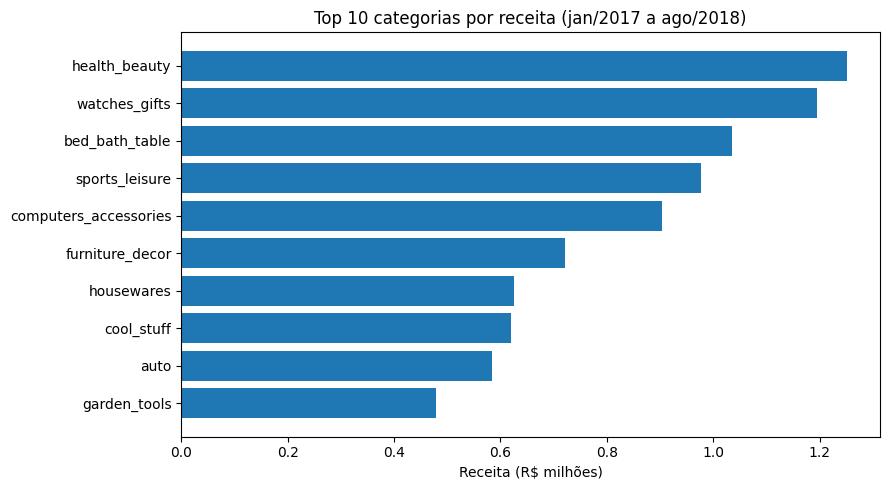

In [151]:
top10 = df_categorias.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10['categoria'], top10['receita'] / 1e6)
ax.set_title('Top 10 categorias por receita (jan/2017 a ago/2018)')
ax.set_xlabel('Receita (R$ milhões)')
plt.tight_layout()
plt.savefig('categoria_receita.png', dpi=150, bbox_inches='tight')
plt.show()